# 5. Bolsa, ouro e o que aconteceu depois do texto

O texto foi publicado em 24 de outubro de 2022 e faz três afirmações que o tempo permite conferir:

- o Ibovespa "não pode ser considerado investimento";
- ouro e bitcoin são as proteções ("hedge") contra a perda;
- a "volta de juro real positivo" é "uma impossibilidade política e física".

As duas primeiras olham para trás e para a frente. A terceira é uma previsão, e já há quase quatro anos de dados
para testá-la.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from juros_negativos import analise, estilo
from juros_negativos.caminhos import TRATADOS
from juros_negativos.estilo import br, pct
from juros_negativos.fontes.afirmacoes import DATA_DO_TEXTO

estilo.aplicar()

brasil = pd.read_parquet(TRATADOS / "brasil.parquet")
paises = pd.read_parquet(TRATADOS / "paises.parquet")
niveis = analise.niveis_do_brasil(brasil)

TEXTO = f"{DATA_DO_TEXTO:%Y-%m}"
FIM = niveis.index[-1] + pd.DateOffset(months=1)
print(f"Texto de {DATA_DO_TEXTO:%d/%m/%Y}; dados até {niveis.index[-1]:%m/%Y}")

Texto de 24/10/2022; dados até 08/2026


## A bolsa foi investimento?

De janeiro de 2008 a agosto de 2026, o Ibovespa subiu 178% e os preços, 179%. Em mais de dezoito anos, quem
comprou o índice empatou com a inflação, e isso já com os dividendos reinvestidos, que o Ibovespa inclui. Nesse
ponto o texto acerta, e nem precisa da régua do M2.

Mas a data pesa. Janeiro de 2008 fica a poucos meses da maior queda recente da bolsa. Em todas as janelas de dez
anos começadas desde então, o Ibovespa rendeu mais que a inflação em 67% delas. E, desde a abertura do real em
1995, rendeu 5,5% ao ano acima dos preços.

In [2]:
linhas = []
for inicio in ["1995-01", "2008-01", "2009-01", "2016-01", TEXTO]:
    v = analise.variacao(niveis, inicio, FIM)
    meses = analise.meses_entre(inicio, FIM)
    linhas.append(
        {
            "desde": f"{inicio[5:]}/{inicio[:4]}",
            "Ibovespa": pct(v["ibovespa"]),
            "IPCA": pct(v["ipca"]),
            "Ibovespa acima da inflação, ao ano": pct(
                analise.anualizar(analise.descontar(v["ibovespa"], v["ipca"]), meses), 1, sinal=True
            ),
            "Selic acima da inflação, ao ano": pct(
                analise.anualizar(analise.descontar(v["selic"], v["ipca"]), meses), 1, sinal=True
            ),
        }
    )
janelas = analise.janelas(niveis, 10)
acima = analise.descontar(janelas["ibovespa"], janelas["ipca"]).dropna().loc["2008-01-01":]
print(
    f"Janelas de 10 anos começadas desde 2008 em que o Ibovespa ganhou da inflação: {pct((acima > 0).mean())} de {len(acima)}"
)
pd.DataFrame(linhas).set_index("desde")

Janelas de 10 anos começadas desde 2008 em que o Ibovespa ganhou da inflação: 67% de 105


,Ibovespa,IPCA,"Ibovespa acima da inflação, ao ano","Selic acima da inflação, ao ano"
desde,,,,
01/1995,3.975%,651%,"+5,5%","+8,0%"
01/2008,178%,179%,"−0,0%","+4,1%"
01/2009,372%,164%,"+3,4%","+4,0%"
01/2016,309%,70%,"+8,6%","+4,3%"
10/2022,61%,20%,"+7,9%","+7,9%"


## R$ 100 em janeiro de 2008, por duas réguas

Os três investimentos do texto, primeiro descontando os preços, depois descontando o M2. O ouro é o único que
ganha das duas réguas: rendeu 9,7% ao ano acima da inflação e 2,5% ao ano acima do M2. O caminho foi irregular:
de 2013 a 2018 ele rendeu 39%, e a Selic, 81%.

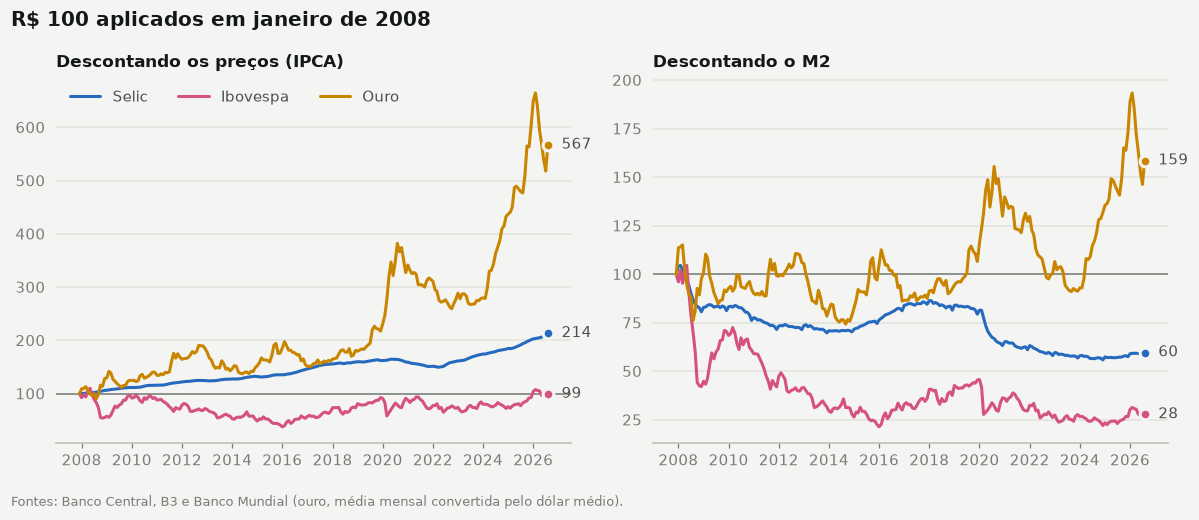

Ouro acima de ipca: +9,7% ao ano
Ouro acima de m2: +2,5% ao ano
De jan/2013 a jan/2019: ouro 39%, Selic 81%


In [3]:
ATIVOS = {"selic": "Selic", "ibovespa": "Ibovespa", "ouro": "Ouro"}
periodo = niveis.loc[pd.Timestamp("2008-01-01") - pd.DateOffset(months=1) :]

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (regua, nome) in zip(eixos, {"ipca": "Descontando os preços (IPCA)", "m2": "Descontando o M2"}.items()):
    for ativo, rotulo in ATIVOS.items():
        indice = periodo[ativo] / periodo[regua]
        ax.plot(100 * indice / indice.iloc[0], color=estilo.cor(ativo), label=rotulo)
    estilo.linha_de_base(ax, 100)
    ax.set_title(nome, loc="left", fontsize=11, fontweight="bold")
    estilo.rotular_fins(ax, lambda v: br(v))
eixos[0].legend(loc="upper left", ncols=3)
fig.suptitle("R$ 100 aplicados em janeiro de 2008", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
estilo.fonte(fig, "Fontes: Banco Central, B3 e Banco Mundial (ouro, média mensal convertida pelo dólar médio).")
plt.show()

desde_2008 = analise.variacao(niveis, "2008-01", FIM)
meses = analise.meses_entre("2008-01", FIM)
for regua in ("ipca", "m2"):
    print(
        f"Ouro acima de {regua}: {pct(analise.anualizar(analise.descontar(desde_2008['ouro'], desde_2008[regua]), meses), 1, sinal=True)} ao ano"
    )
parado = analise.variacao(niveis, "2013-01", "2019-01")
print(f"De jan/2013 a jan/2019: ouro {pct(parado['ouro'])}, Selic {pct(parado['selic'])}")

## Proteção, mas com que quedas?

Render mais que as réguas é metade da pergunta. A outra metade é o caminho: quanto cada um caiu entre um recorde
e o recorde seguinte. A conta usa o preço em reais do último dia de cada mês (no ouro, a média do mês), então o
que cai e volta dentro do mês não aparece, e as quedas de verdade são um pouco maiores.

Desde 2011, o bitcoin perdeu mais da metade do valor **cinco vezes**: 80% em 2011, 77% de 2013 a 2015, 70% de
2017 a 2019, 75% de 2021 a 2022 e 53% de julho de 2025 a junho de 2026, esta última já depois do texto. Quando o
texto foi publicado, ele estava 70% abaixo do recorde.

O ouro caiu perto de 20% seis vezes desde 2008, e nunca mais que isso.

A data da compra decide o resultado. Quem comprou bitcoin no pico de outubro de 2021 tem hoje 16% a mais, contra
uma inflação de 27% e uma Selic de 78% no mesmo período.

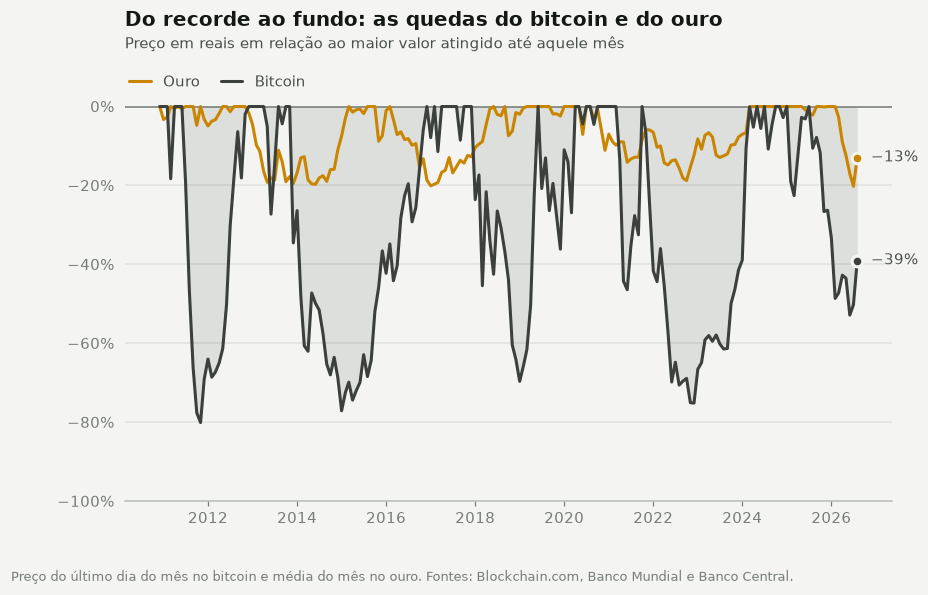

Bitcoin: 5 quedas de mais da metade do valor desde 2011; no fim de 09/2022, a −70% do recorde
Ouro: 6 quedas de mais de 15% desde 2008; a maior, de −20%
Bitcoin depois do texto: −53% de 07/2025 a 06/2026
Quem comprou bitcoin no fim de 10/2021: +16% até 08/2026; IPCA +27%, Selic +78%


,recorde,fundo,queda
ativo,,,
Bitcoin,06/2011,11/2011,−80%
Bitcoin,11/2013,01/2015,−77%
Bitcoin,12/2017,01/2019,−70%
Bitcoin,10/2021,12/2022,−75%
Bitcoin,07/2025,06/2026,−53%
Ouro,03/2008,08/2008,−18%
Ouro,02/2009,08/2009,−20%
Ouro,11/2012,06/2014,−20%
Ouro,02/2016,01/2017,−20%


In [4]:
DESDE = "2011-01"  # o primeiro ano inteiro com preço do bitcoin
grandes = analise.quedas(niveis, "bitcoin", DESDE, FIM, minima=0.5)
do_ouro = analise.quedas(niveis, "ouro", "2008-01", FIM, minima=0.15)

distancias = pd.DataFrame(
    {
        nome: analise.distancia_do_pico(niveis, serie, DESDE, FIM)
        for serie, nome in {"ouro": "Ouro", "bitcoin": "Bitcoin"}.items()
    }
)
fig, ax = plt.subplots()
ax.fill_between(distancias.index, distancias["Bitcoin"], 0, color=estilo.GRAFITE, alpha=0.12, lw=0)
ax.plot(distancias["Ouro"], color=estilo.cor("ouro"), label="Ouro")
ax.plot(distancias["Bitcoin"], color=estilo.GRAFITE, label="Bitcoin")
estilo.linha_de_base(ax)
estilo.titulo(
    ax,
    "Do recorde ao fundo: as quedas do bitcoin e do ouro",
    "Preço em reais em relação ao maior valor atingido até aquele mês",
    legenda=True,
)
estilo.eixo_pct(ax.yaxis)
ax.set_ylim(-1, 0.03)
estilo.rotular_fins(ax, lambda v: pct(v))
estilo.fonte(
    fig,
    "Preço do último dia do mês no bitcoin e média do mês no ouro. Fontes: Blockchain.com, Banco Mundial e Banco Central.",
)
plt.show()

vespera = pd.Timestamp(TEXTO) - pd.DateOffset(months=1)
print(
    f"Bitcoin: {len(grandes)} quedas de mais da metade do valor desde 2011; no fim de {vespera:%m/%Y}, a {pct(distancias.loc[vespera, 'Bitcoin'])} do recorde"
)
print(f"Ouro: {len(do_ouro)} quedas de mais de 15% desde 2008; a maior, de {pct(do_ouro['queda'].min())}")

depois = analise.quedas(niveis, "bitcoin", TEXTO, FIM)
pior = depois.loc[depois["queda"].idxmin()]
print(f"Bitcoin depois do texto: {pct(pior['queda'])} de {pior['pico']:%m/%Y} a {pior['fundo']:%m/%Y}")

pico = grandes[grandes["pico"] < DATA_DO_TEXTO]["pico"].iloc[-1]  # o último recorde antes do texto
desde_o_pico = niveis.iloc[-1] / niveis.loc[pico] - 1
print(
    f"Quem comprou bitcoin no fim de {pico:%m/%Y}: {pct(desde_o_pico['bitcoin'], sinal=True)} até {niveis.index[-1]:%m/%Y}; "
    f"IPCA {pct(desde_o_pico['ipca'], sinal=True)}, Selic {pct(desde_o_pico['selic'], sinal=True)}"
)

todas = pd.concat([grandes.assign(ativo="Bitcoin"), do_ouro.assign(ativo="Ouro")])
pd.DataFrame(
    {
        "ativo": todas["ativo"],
        "recorde": todas["pico"].dt.strftime("%m/%Y"),
        "fundo": todas["fundo"].dt.strftime("%m/%Y"),
        "queda": todas["queda"].map(lambda v: pct(v)),
    }
).set_index("ativo")

## Depois do texto

De outubro de 2022 a agosto de 2026:

- a **Selic** rendeu 62% e a inflação foi de 20%: um juro real de 7,9% ao ano;
- o **M2** cresceu 60%, praticamente o mesmo que a Selic e o Ibovespa (61%). Até pela régua do texto, o "juro
  negativo" sumiu;
- o **ouro** subiu 158% em reais e o **bitcoin**, 280%;
- o **dólar** caiu 4%.

A previsão de que o juro real positivo não voltaria falhou logo em seguida. As proteções que o texto recomenda
renderam mais que tudo, com as quedas da seção anterior no caminho: o bitcoin caiu 53% entre julho de 2025 e junho
de 2026.

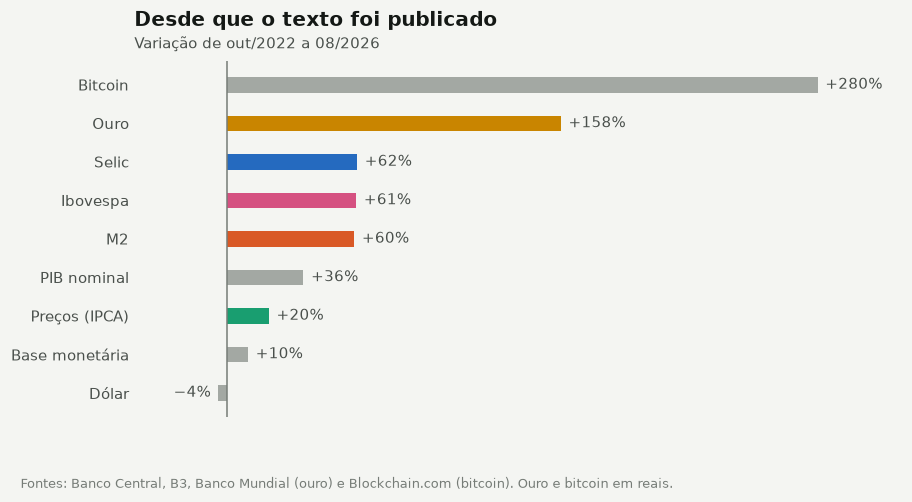

Selic acima de ipca desde o texto: +7,9% ao ano
Selic acima de m2 desde o texto: +0,2% ao ano


In [5]:
desde_o_texto = analise.variacao(niveis, TEXTO, FIM)
ATIVOS_E_REGUAS = {
    "bitcoin": "Bitcoin",
    "ouro": "Ouro",
    "selic": "Selic",
    "ibovespa": "Ibovespa",
    "m2": "M2",
    "pib": "PIB nominal",
    "ipca": "Preços (IPCA)",
    "base_monetaria": "Base monetária",
    "dolar": "Dólar",
}
barras = desde_o_texto[list(ATIVOS_E_REGUAS)].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.2))
estilo.barras(
    ax, barras.rename(ATIVOS_E_REGUAS), [estilo.cor(serie) for serie in barras.index], lambda v: pct(v, sinal=True)
)
estilo.titulo(ax, "Desde que o texto foi publicado", f"Variação de out/2022 a {niveis.index[-1]:%m/%Y}")
estilo.fonte(
    fig, "Fontes: Banco Central, B3, Banco Mundial (ouro) e Blockchain.com (bitcoin). Ouro e bitcoin em reais."
)
plt.show()

meses = analise.meses_entre(TEXTO, FIM)
for regua in ("ipca", "m2"):
    print(
        f"Selic acima de {regua} desde o texto: {pct(analise.anualizar(analise.descontar(desde_o_texto['selic'], desde_o_texto[regua]), meses), 1, sinal=True)} ao ano"
    )

## O juro real brasileiro hoje

Nos 12 meses até agosto de 2026, a Selic rendeu 14,6% e a inflação foi de 4,2%: juro real de 10,0%. Entre os 17
países do notebook anterior, o Brasil teve o juro real mais alto em 2025.

In [6]:
juro_real = analise.juro_real_12m(brasil).iloc[-1]
print(
    f"12 meses até {niveis.index[-1]:%m/%Y}: Selic {pct(juro_real['selic_12m'], 1)}, IPCA {pct(juro_real['ipca_12m'], 1)}, juro real {pct(juro_real['real_ipca'], 1)}"
)

em_2025 = paises[paises["data"].dt.year == 2025].groupby("pais")["juro_real_aa"].mean().sort_values(ascending=False)
em_2025.head(5).map(lambda v: pct(v, 1)).rename("juro real médio em 2025").to_frame()

12 meses até 08/2026: Selic 14,6%, IPCA 4,2%, juro real 10,0%


,juro real médio em 2025
pais,
Brasil,"9,1%"
Turquia,"5,7%"
México,"4,3%"
Colômbia,"4,0%"
África do Sul,"3,8%"


## O que fica deste notebook

1. **Sobre a bolsa, o texto acerta em parte.** O Ibovespa empatou com a inflação de 2008 a 2026. Mas o ponto de
   partida é o pico de 2008; em janelas de dez anos, a bolsa ganhou da inflação em dois terços das vezes.
2. **Sobre o ouro e o bitcoin, acerta em parte.** O ouro foi o único dos três investimentos a ganhar do M2 desde
   2008, e a maior queda dele foi de 20%. O bitcoin rendeu muito mais e disparou depois do texto, mas perdeu mais da
   metade do valor cinco vezes desde 2011, uma delas já depois do texto. Uma proteção assim depende do dia da
   compra e de poder esperar a volta.
3. **A previsão sobre o juro real falhou.** Desde o texto, a Selic rendeu 7,9% ao ano acima da inflação, e empatou
   até com o M2.